In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

import keras
from keras.models import Sequential
from keras.layers import Dense, Input
print(keras.__version__, keras.backend.backend())

3.15.1 torch


In [3]:
import importlib
for m in ['sklearn.linear_model', 'sklearn.ensemble', 'sklearn.metrics',
          'sklearn.datasets', 'sklearn.model_selection', 'sklearn.preprocessing']:
    try:
        importlib.import_module(m)
        print('OK     ', m)
    except Exception:
        print('BLOCKED', m)

OK      sklearn.linear_model
OK      sklearn.ensemble
OK      sklearn.metrics
OK      sklearn.datasets
OK      sklearn.model_selection
OK      sklearn.preprocessing


In [4]:
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.summary()
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.2)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2665 - loss: 0.9351 - val_accuracy: 0.3956 - val_loss: 0.7739
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4698 - loss: 0.7238 - val_accuracy: 0.6044 - val_loss: 0.6408
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6813 - loss: 0.5990 - val_accuracy: 0.8242 - val_loss: 0.5562
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8379 - loss: 0.5175 - val_accuracy: 0.9231 - val_loss: 0.4959
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9286 - loss: 0.4532 - val_accuracy: 0.9341 - val_loss: 0.4412
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9505 - loss: 0.3902 - val_accuracy: 0.9341 - val_loss: 0.3807
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9615 - loss: 0.3231 - val_accuracy: 0.9451 - val_loss: 0.3075
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9643 - loss: 0.2553 - val_accuracy: 0.9560 - v

In [7]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9737 - loss: 0.0736
Test Loss: 0.07362738251686096
Test Accuracy: 0.9736841917037964


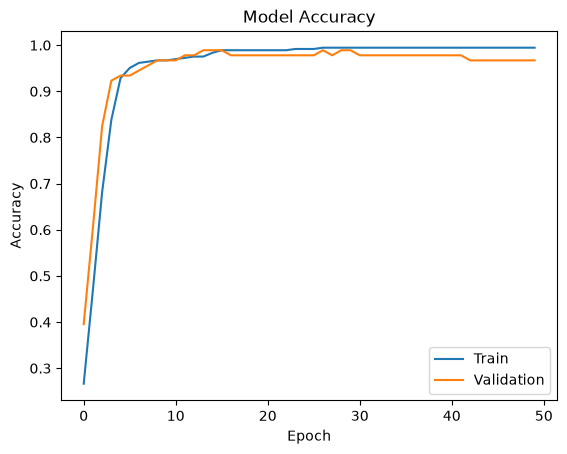

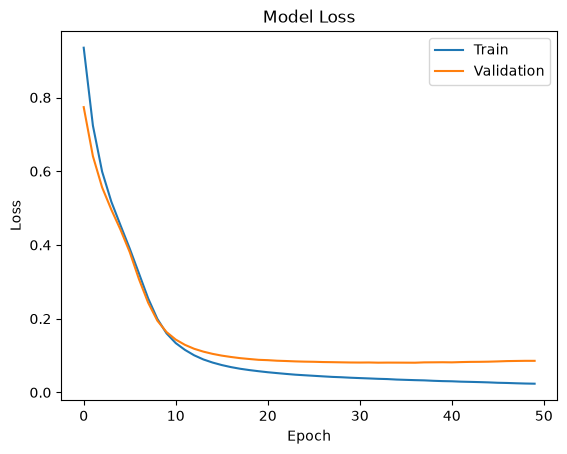

In [8]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.savefig('accuracy_graph.png')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.savefig('loss_graph.png')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
                 Model  Accuracy
0  Logistic Regression  0.973684
1        Random Forest  0.964912
2       Neural Network  0.973684


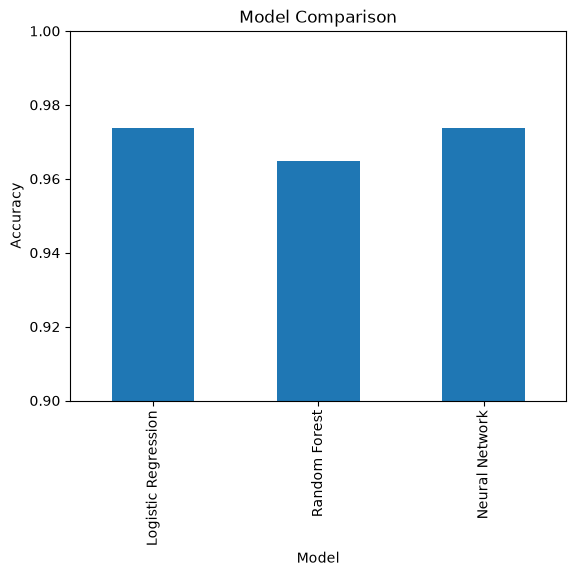

In [9]:
lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
nn_pred = (model.predict(X_test) > 0.5).astype(int).ravel()

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Neural Network'],
    'Accuracy': [accuracy_score(y_test, lr.predict(X_test)),
                 accuracy_score(y_test, rf.predict(X_test)),
                 accuracy_score(y_test, nn_pred)]
})
print(results)
results.plot(x='Model', y='Accuracy', kind='bar', legend=False, ylim=(0.9, 1.0))
plt.title('Model Comparison'); plt.ylabel('Accuracy')
plt.savefig('comparison.png')
plt.show()